# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Amelia Chen, Lawson Pham

**Date:** 11/02/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.

############## STEP 1 ##############

import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()


In [9]:
''' 
2. What is the shape of `X_train` and `X_test`? 
What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? 
What is the shape of `y_train` and `y_test`?
'''

print("X_train shape: ", X_train.shape)
print("X_test shape: ", X_test.shape)

for i in range(10):
    print("index: ", i)
    print("X_train shape: ", X_train[i].shape)
    print("X_test shape: ", X_test[i].shape)

print("y_train shape: ", y_train.shape)
print("y_test shape: ", y_test.shape)


X_train shape:  (60000, 28, 28)
X_test shape:  (10000, 28, 28)
index:  0
X_train shape:  (28, 28)
X_test shape:  (28, 28)
index:  1
X_train shape:  (28, 28)
X_test shape:  (28, 28)
index:  2
X_train shape:  (28, 28)
X_test shape:  (28, 28)
index:  3
X_train shape:  (28, 28)
X_test shape:  (28, 28)
index:  4
X_train shape:  (28, 28)
X_test shape:  (28, 28)
index:  5
X_train shape:  (28, 28)
X_test shape:  (28, 28)
index:  6
X_train shape:  (28, 28)
X_test shape:  (28, 28)
index:  7
X_train shape:  (28, 28)
X_test shape:  (28, 28)
index:  8
X_train shape:  (28, 28)
X_test shape:  (28, 28)
index:  9
X_train shape:  (28, 28)
X_test shape:  (28, 28)
y_train shape:  (60000,)
y_test shape:  (10000,)


The shape of X_train is (60000, 28, 28). The shape of X_test is (10000, 28, 28). The shape of each i in X_train and X_test is (28, 28). The shape of Y_train is (60000, ). The shape of Y_test is (10000,).

In [9]:
'''
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. 
So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length 
row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for 
scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
'''

############## STEP 3 ##############

X_train_flat = X_train.reshape(X_train.shape[0], 784)
X_test_flat = X_test.reshape(X_test.shape[0], 784)

In [1]:
''' 
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal 
number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
'''

from sklearn.neighbors import KNeighborsClassifier

for k in [1, 3, 5, 7, 9, 11, 13, 15]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_flat, y_train)
    accuracy = knn.score(X_test_flat, y_test)
    print(f"k={k}, Accuracy={accuracy}")

NameError: name 'X_train_flat' is not defined

k = 3 looks like the optimal number of neighbors, with the highest accuracy of 97.05%

Accuracy=0.9705


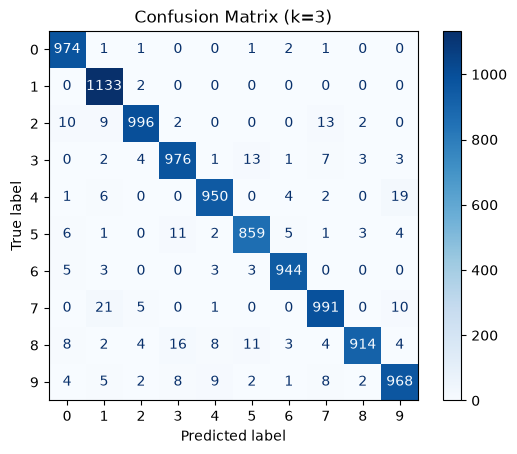

In [ ]:
''' 
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, 
compute a confusion matrix, and explain your findings.
'''
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_flat, y_train)
y_pred = knn.predict(X_test_flat)
accuracy = accuracy_score(y_test, y_pred)

conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Accuracy={accuracy}")
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"])
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix (k=3)")
plt.grid(False)
plt.show()

The accuracy is 97.05%. The findings show that it has a high accuracy of predicting the digits, with predictions for the diagonal having over 900 predictions while the other mistake columns do not reach over 30 predictions. This shows that the model and k value is strong since the diagonals have the most values.

##### 6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
The mistakes that are most liekly are between 1 and 7, where in the confusion matrix, 7 had 1.77% prediction when the number was 1, the highest compared to any other value. Another mistake that is most likely is 4 and 9, where 4 had a 1.88% chance of getting predicted when the number was 9. This shows an interesting pattern because the numbers also look the most similar, with 7 looking like an elongated version of 1 and 9 looking like connecting the top of the 4. With handwritten numbers, this can cause the model to group them together since it can look very similar.


##### 7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

To represent a color photo in matrix form, we can take the RBG values and convert them to their hexadecimal format, which can then be stored in an integer. For example, a sky blue color has RBG codes R=105, G=185, and B=250, which is equivalent to the hexademical #69b9fa. Converting this to an int, we get the value of 6928890. To convert the matrix to tabular data, we can reshape the matrix into a vector by just appending each row to the end of the first row in order.

A color photo can be represented as a 3D matrix using RGB values, where each pixel has 3 values representing red, green, and blue from 0 to 255. For example, a 28x28 color photo would have a shape of (28, 28, 3). Each position in the matrix represents a pixel, and the 3 values determine its color. For example, (255, 0, 0) would represent a red pixel and (0, 0, 255) would represent a blue pixel. To convert this into tabular data, we can reshape the matrix into a single row of 2352 values since 28x28x3 = 2352. Each row would represent one photo, and each column would represent one RGB value of a pixel. This allows us to use the image as tabular data for machine learning.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 
- **AI tool and model used:** ChatGPT 6

### *Prompts used

Review my assignment and Phase 1 solution. Identify any mistakes, suggest improvements, and explain why those changes would help. Keep the suggestions simple and provide a numbered list of recommended changes.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]